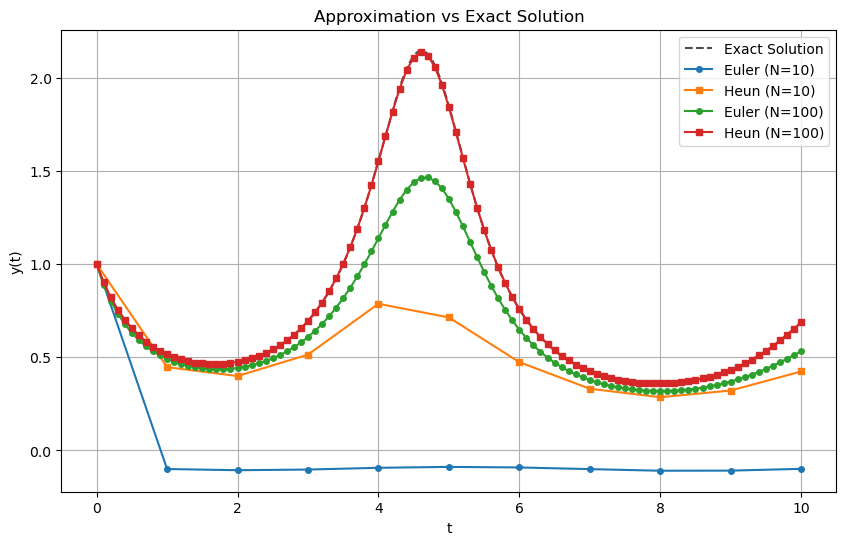

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

# Setup the IVP
f = lambda t, y: -(0.1 + np.cos(t)) * (y**2)
y_exact = lambda t: 1 / (1 + t/10 + np.sin(t))
t0, y0 = 0, 1
T = 10

# evolve & increment function
def evolve(t0, y0, f, Phi, h, N):
    u = np.zeros(N + 1)
    u[0] = y0
    t = t0
    for i in range(N):
        u[i+1] = u[i] + h * np.asarray(Phi(t, u[i], f, h)).item()
        t += h
    return u

def forward_euler(t, u, f, h):
    return f(t, u)

def heun(t, u, f, h):
    k1 = f(t, u)
    k2 = f(t + h, u + h * k1)
    return 0.5 * (k1 + k2)

N_list = [10, 100]
t_fine = np.linspace(0, T, 500)
plt.figure(figsize=(10, 6))
plt.plot(t_fine, y_exact(t_fine), 'k--', label="Exact Solution", alpha=0.7)

#plot
for N in N_list:
    h = T / N
    t_grid = np.linspace(0, T, N + 1)
    
    u_euler = evolve(t0, y0, f, forward_euler, h, N)
    u_heun = evolve(t0, y0, f, heun, h, N)
    
    plt.plot(t_grid, u_euler, 'o-', label=f"Euler (N={N})", markersize=4)
    plt.plot(t_grid, u_heun, 's-', label=f"Heun (N={N})", markersize=4)

plt.xlabel("t")
plt.ylabel("y(t)")
plt.title("Approximation vs Exact Solution")
plt.legend()
plt.grid(True)
plt.show()

$N=10$ vs $N=100$ :  
At $N=10$, both methods show visible deviation from the exact solution because the step size h=1 is too large to capture the oscillations of the $\cos(t)$ term accurately. At $N=100$, the Heun method becomes almost indistinguishable from the exact solution on the plot, while Euler still shows a small, though much improved, deviation.  
$Euler$ vs $Heun$ :  
Forward Euler is a first-order method ($p=1$). Its error decreases linearly with $h$. Heun's Method is a second-order method ($p=2$). It is significantly more accurate for the same number of steps because it accounts for the curvature of the solution by averaging the slopes at the beginning and end of the interval. Also when the step size decreases, Heun's method converges much faster.  

In [75]:
# Last error Function
def lastError(Phi, h, N):
    t_end = t0 + N * h
    u = evolve(t0, y0, f, Phi, h, N)
    return np.abs(u[-1] - y_exact(t_end))

In [76]:
def EOC(hs, errs):
    eoc = np.zeros(len(errs))
    eoc[0] = np.nan 
    for i in range(1, len(errs)):
        # EOC = log(err_{i-1}/err_i) / log(h_{i-1}/h_i)
        eoc[i] = np.log(errs[i-1] / errs[i]) / np.log(hs[i-1] / hs[i])
    return eoc

### Convergence Table: Forward Euler
| $h$ | Error | EOC |
|:---|:---|:---|
| 2.5000 | 9.8828e+01 | --- |
| 1.2500 | 9.3028e-01 | 6.7311 |
| 0.6250 | 4.5964e-01 | 1.0172 |
| 0.3125 | 3.1513e-01 | 0.5446 |
| 0.1562 | 2.0989e-01 | 0.5863 |
| 0.0781 | 1.2840e-01 | 0.7090 |
| 0.0391 | 7.2855e-02 | 0.8175 |
| 0.0195 | 3.9172e-02 | 0.8952 |
| 0.0098 | 2.0370e-02 | 0.9433 |
| 0.0049 | 1.0396e-02 | 0.9704 |
| 0.0024 | 5.2527e-03 | 0.9849 |


### Convergence Table: Heun
| $h$ | Error | EOC |
|:---|:---|:---|
| 2.5000 | 1.5865e+27 | --- |
| 1.2500 | 4.1849e-01 | 91.6147 |
| 0.6250 | 5.0242e-02 | 3.0582 |
| 0.3125 | 9.1622e-03 | 2.4551 |
| 0.1562 | 3.0544e-03 | 1.5848 |
| 0.0781 | 7.7434e-04 | 1.9799 |
| 0.0391 | 1.9223e-04 | 2.0101 |
| 0.0195 | 4.7789e-05 | 2.0081 |
| 0.0098 | 1.1909e-05 | 2.0046 |
| 0.0049 | 2.9724e-06 | 2.0024 |
| 0.0024 | 7.4248e-07 | 2.0012 |


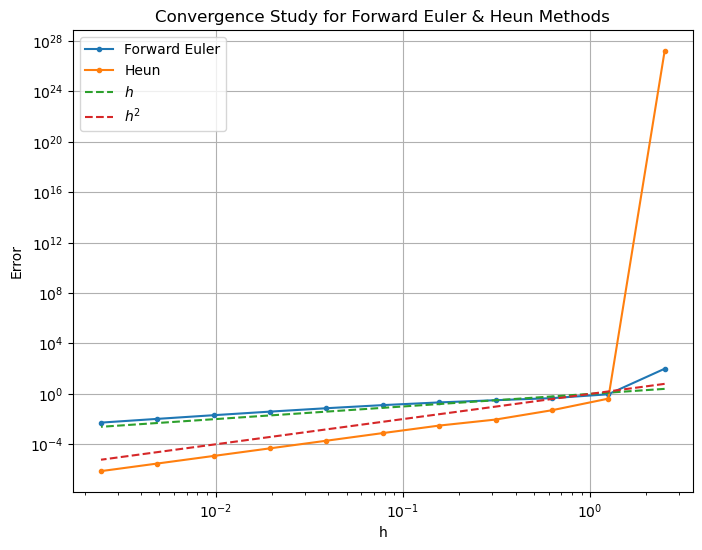

In [77]:
N0 = 4
ks = np.arange(11)
Nks = N0 * (2**ks)
hs = T / Nks

errs_euler = [lastError(forward_euler, h, int(n)) for h, n in zip(hs, Nks)]
errs_heun = [lastError(heun, h, int(n)) for h, n in zip(hs, Nks)]

eoc_euler = EOC(hs, errs_euler)
eoc_heun = EOC(hs, errs_heun)

for name, errs, eocs in [("Forward Euler", errs_euler, eoc_euler), ("Heun", errs_heun, eoc_heun)]:
    table = f"### Convergence Table: {name}\n"
    table += "| $h$ | Error | EOC |\n|:---|:---|:---|\n"
    for h, err, eoc in zip(hs, errs, eocs):
        eoc_val = "---" if np.isnan(eoc) else f"{eoc:.4f}"
        table += f"| {h:.4f} | {err:.4e} | {eoc_val} |\n"
    display(Markdown(table))
  
plt.figure(figsize=(8, 6))
plt.loglog(hs, es_euler, '.-', label="Forward Euler")
plt.loglog(hs, es_heun, '.-', label="Heun")
plt.loglog(hs, hs, '--', label="$h$")
plt.loglog(hs, hs**2, '--', label="$h^2$")
plt.xlabel("h")
plt.ylabel("Error")
plt.legend()
plt.grid(True)
plt.title("Convergence Study for Forward Euler & Heun Methods")
plt.show()

Forward Euler method:    
The EOC values approach 1 as the step size decreases.The log–log plot shows the error curve parallel to the $O(h)$ reference line. This confirms that Euler is first-order accurate.
Heun method:  
The EOC values approach 2 for small h. The log–log plot shows the error curve parallel to the $O(h^2)$ reference line. This confirms that Heun is second-order accurate.

In [78]:
def explicitRK(t, u, f, h, A, b, c):
    s = len(b)
    A = np.array(A)
    b = np.array(b)
    c = np.array(c)
    
    ks = np.zeros((s, np.size(u))) 
    for i in range(s):
        incremental_sum = np.dot(A[i, :i], ks[:i])
        ks[i] = f(t + c[i] * h, u + h * incremental_sum)
    
    return np.dot(b, ks)

def forward_euler_rk(t, u, f, h):
    A = [[0]]
    b = [1]
    c = [0]
    return explicitRK(t, u, f, h, A, b, c)

def explicit_midpoint(t, u, f, h):
    A = [[0, 0], 
         [1/2, 0]]
    b = [0, 1]
    c = [0, 1/2]
    return explicitRK(t, u, f, h, A, b, c)

def RK3(t, u, f, h):
    A = [[0, 0, 0], 
         [1/2, 0, 0], 
         [-1, 2, 0]]
    b = [1/6, 2/3, 1/6]
    c = [0, 1/2, 1]
    return explicitRK(t, u, f, h, A, b, c)

C:\Users\27126\AppData\Local\Temp\ipykernel_25388\1753604754.py:8: RuntimeWarning: overflow encountered in square
  f = lambda t, y: -(0.1 + np.cos(t)) * (y**2)


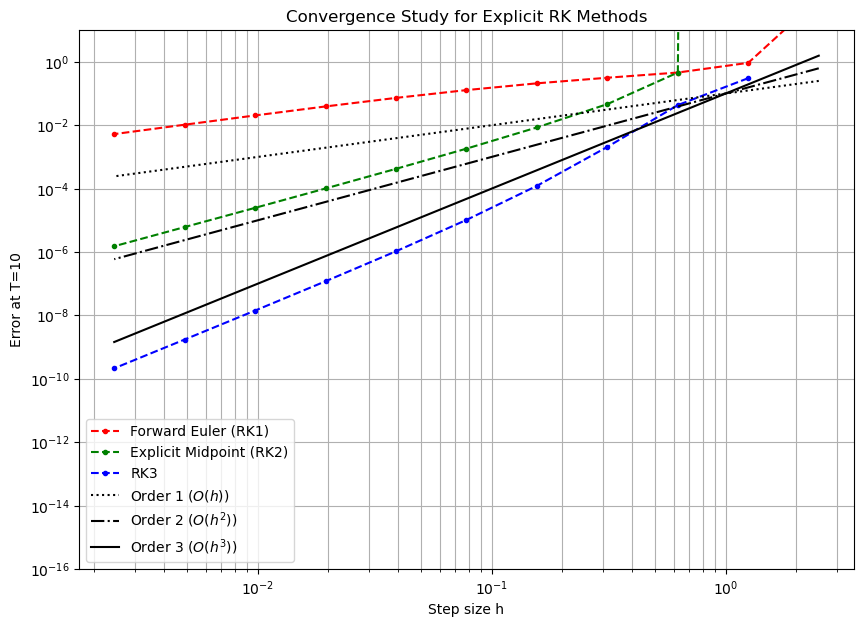

### EOC Table: Forward Euler (RK1)
| $h$ | Error | EOC |
|:---|:---|:---|
| 2.5000 | 9.8828e+01 | --- |
| 1.2500 | 9.3028e-01 | 6.7311 |
| 0.6250 | 4.5964e-01 | 1.0172 |
| 0.3125 | 3.1513e-01 | 0.5446 |
| 0.1562 | 2.0989e-01 | 0.5863 |
| 0.0781 | 1.2840e-01 | 0.7090 |
| 0.0391 | 7.2855e-02 | 0.8175 |
| 0.0195 | 3.9172e-02 | 0.8952 |
| 0.0098 | 2.0370e-02 | 0.9433 |
| 0.0049 | 1.0396e-02 | 0.9704 |
| 0.0024 | 5.2527e-03 | 0.9849 |


### EOC Table: Explicit Midpoint (RK2)
| $h$ | Error | EOC |
|:---|:---|:---|
| 2.5000 | 8.4482e+07 | --- |
| 1.2500 | 3.7215e+254 | -819.3335 |
| 0.6250 | 4.5996e-01 | 846.7860 |
| 0.3125 | 4.6426e-02 | 3.3085 |
| 0.1562 | 8.5266e-03 | 2.4449 |
| 0.0781 | 1.8271e-03 | 2.2224 |
| 0.0391 | 4.2205e-04 | 2.1141 |
| 0.0195 | 1.0134e-04 | 2.0582 |
| 0.0098 | 2.4824e-05 | 2.0294 |
| 0.0049 | 6.1425e-06 | 2.0148 |
| 0.0024 | 1.5277e-06 | 2.0074 |


### EOC Table: RK3
| $h$ | Error | EOC |
|:---|:---|:---|
| 2.5000 | inf | --- |
| 1.2500 | 3.0561e-01 | inf |
| 0.6250 | 4.3218e-02 | 2.8220 |
| 0.3125 | 2.0746e-03 | 4.3807 |
| 0.1562 | 1.2280e-04 | 4.0785 |
| 0.0781 | 1.0324e-05 | 3.5723 |
| 0.0391 | 1.0586e-06 | 3.2857 |
| 0.0195 | 1.2000e-07 | 3.1410 |
| 0.0098 | 1.4293e-08 | 3.0697 |
| 0.0049 | 1.7442e-09 | 3.0346 |
| 0.0024 | 2.1544e-10 | 3.0172 |


In [79]:
rk_methods = [
    ("Forward Euler (RK1)", forward_euler_rk),
    ("Explicit Midpoint (RK2)", explicit_midpoint),
    ("RK3", RK3)
]

all_errors = {}
for name, Phi in rk_methods:
    all_errors[name] = [lastError(Phi, h, int(n)) for h, n in zip(hs, Nks)]

plt.figure(figsize=(10, 7))
colors = ['r', 'g', 'b']
for i, (name, errs) in enumerate(all_errors.items()):
    plt.loglog(hs, errs, f'{colors[i]}.--', label=name)

plt.loglog(hs, 1e-1 * hs, 'k:', label="Order 1 ($O(h)$)")
plt.loglog(hs, 1e-1 * hs**2, 'k-.', label="Order 2 ($O(h^2)$)")
plt.loglog(hs, 1e-1 * hs**3, 'k-', label="Order 3 ($O(h^3)$)")

plt.ylim(1e-16, 1e1)
plt.xlabel("Step size h")
plt.ylabel("Error at T=10")
plt.title("Convergence Study for Explicit RK Methods")
plt.legend()
plt.grid(True, which="both", ls="-")
plt.show()

for name, errs in all_errors.items():
    eocs = EOC(hs, errs)
    table = f"### EOC Table: {name}\n"
    table += "| $h$ | Error | EOC |\n|:---|:---|:---|\n"
    for h, err, eoc in zip(hs, errs, eocs):
        eoc_val = "---" if np.isnan(eoc) else f"{eoc:.4f}"
        table += f"| {h:.4f} | {err:.4e} | {eoc_val} |\n"
    display(Markdown(table))

In our implementation, the observed orders match the number of stages ($p=s$) for all three methods. We know that order of an explicit $s$ stage RK method is at most $s$ thus these methods have maximal orders.

In [80]:
def embeddedRK(t, u, f, h, A, b, bhat, c):
    s = len(b)
    A = np.array(A)
    b = np.array(b)
    bhat = np.array(bhat)
    c = np.array(c)
    
    ks = np.zeros((s, np.size(u)))
    for i in range(s):
        incremental_sum = np.dot(A[i, :i], ks[:i])
        ks[i] = f(t + c[i] * h, u + h * incremental_sum)
    
    phi = np.dot(b, ks)
    phi_hat = np.dot(bhat, ks)
    return phi, phi_hat

def embeddedEvolve(t0, y0, f, embeddedPhi, h, N):
    u = np.zeros(N + 1)
    tau = np.zeros(N + 1) 
    u[0] = y0
    t = t0
    
    for i in range(N):
        phi, phi_hat = embeddedPhi(t, u[i], f, h)
        u[i+1] = u[i] + h * phi_hat.item()
        tau[i+1] = h * np.abs((phi_hat - phi).item())
        t += h
    return u, tau

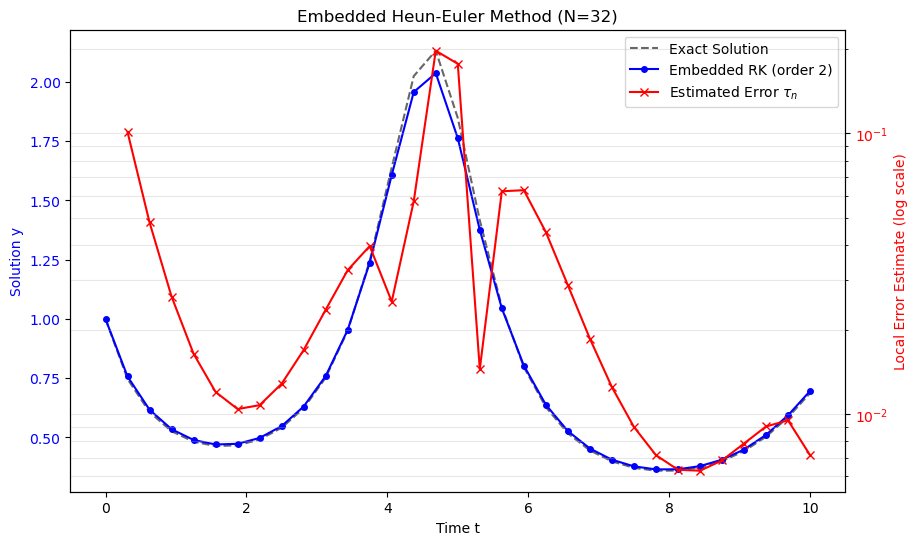

In [81]:
def heun_euler_embedded(t, u, f, h):
    A = [[0, 0], [1, 0]]
    b = [1, 0]        # Forward Euler (Order 1)
    bhat = [1/2, 1/2] # Heun (Order 2)
    c = [0, 1]
    return embeddedRK(t, u, f, h, A, b, bhat, c)

N = 32
T = 10
h = T / N
t_grid = np.linspace(0, T, N + 1)

u_vals, tau_vals = embeddedEvolve(t0, y0, f, heun_euler_embedded, h, N)
y_true = y_exact(t_grid)

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(t_grid, y_true, 'k--', label="Exact Solution", alpha=0.6)
ax1.plot(t_grid, u_vals, 'b-o', label="Embedded RK (order 2)", markersize=4)
ax1.set_xlabel("Time t")
ax1.set_ylabel("Solution y", color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.semilogy(t_grid[1:], tau_vals[1:], 'r-x', label="Estimated Error $\\tau_n$")
ax2.set_ylabel("Local Error Estimate (log scale)", color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax2.set_title(f"Embedded Heun-Euler Method (N={N})")

plt.grid(True, which="both", ls="-", alpha=0.3)
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
plt.show()

An adaptive algorithm would decrease the timestep when the red line (local error) exceeds a set threshold.  
Increase timestep around $t=5$: The solution $y$ enters a steep peak.The error $\tau_n$ shoots up above $10^{-1}$. 

The algorithm would increase the timestep when the error is significantly lower than the allowed tolerance to save on computation.  
Decrease timestep around $t=8$: The solution is at a global minimum and is quite flat. The error drops below $10^{-2}$.

In [82]:
def getR(A, b, c):
    A = np.array(A)
    b = np.array(b)
    s = len(b)
    eye = np.eye(s)
    ones = np.ones(s)
    
    def R(z):
        inv_term = np.linalg.solve(eye - z * A, ones)
        return 1 + z * np.dot(b, inv_term)
    
    return R

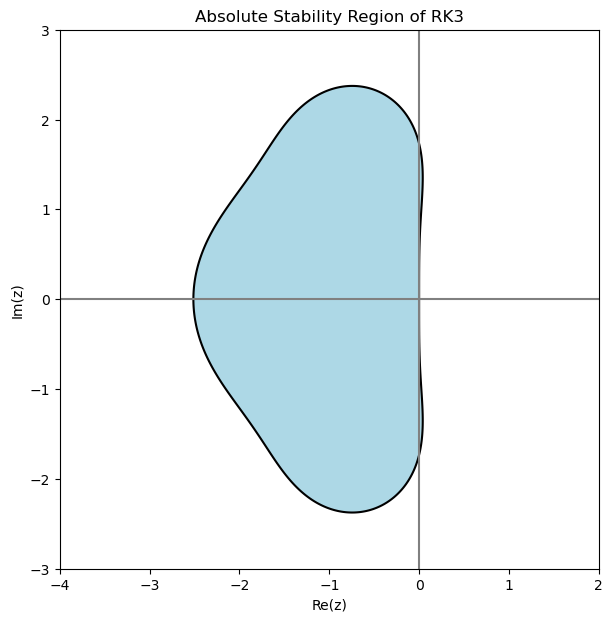

In [55]:
A_rk3 = [[0, 0, 0], [1/2, 0, 0], [-1, 2, 0]]
b_rk3 = [1/6, 2/3, 1/6]
c_rk3 = [0, 1/2, 1]

R_func = getR(A_rk3, b_rk3, c_rk3)

x = np.linspace(-4, 2, 400)
y = np.linspace(-3, 3, 400)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

R_abs = np.zeros_like(Z, dtype=float)
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        R_abs[i, j] = np.abs(R_func(Z[i, j]))

plt.figure(figsize=(7,7))

plt.contourf(X, Y, R_abs, levels=[0,1], colors=["lightblue"])

plt.contour(X, Y, R_abs, levels=[1], colors="black")

plt.axhline(0, color='gray')
plt.axvline(0, color='gray')

plt.xlabel("Re(z)")
plt.ylabel("Im(z)")

plt.title("Absolute Stability Region of RK3")

plt.gca().set_aspect('equal')

plt.show()
